In [19]:
import math
import numpy as np
import matplotlib.pyplot as plt
import japanize_matplotlib

In [20]:
np.random.seed(0)

In [21]:
alpha = 11
lam = 13

epsilon = 0.01
L = 100

# HMC の実行回数
T = 100000

In [22]:
x = np.array([
	162, 172, 178, 154, 173, 174, 166, 166, 166, 164,
	167, 163, 165, 170, 177, 169, 166, 164, 164, 187,
	171, 167, 167, 173, 165, 160, 174, 163, 170, 163,
	178, 167, 165, 166, 159, 162, 155, 161, 168, 167,
	180, 163, 164, 168, 163, 163, 162, 161, 166, 167,
	157, 166, 162, 163, 169, 174, 182, 165, 181, 162,
	175, 188, 170, 165, 170, 182, 162, 180, 179, 172,
	170, 167, 167, 175, 184, 169, 160, 165, 172, 168,
	169, 169, 160, 169, 176, 175, 174, 167, 169, 162,
	170, 172, 182, 177, 167, 172, 162, 176, 177, 185
], dtype=float)

n = len(x)

print("データ数 =", n)
print("標本平均 =", np.mean(x))
print("標本分散 =", np.var(x))

データ数 = 100
標本平均 = 168.96
標本分散 = 48.8784


# リープフロッグでの遷移

In [23]:
# 式5.59
def h(theta):
	mu, sigma2 = theta
	return n / 2 * np.log(sigma2) + (1 / (2*sigma2)) * np.sum((x - mu)**2)

# 式5.60, 5.61
def dh(theta):
	mu, sigma2 = theta

	sum_sq = np.sum((x - mu)**2)

	# μについての微分
	dh_dmu = -np.sum(x - mu) / sigma2

	# σ^2についての微分
	dh_dsigma2 = (
		n / (2 * sigma2)
		- sum_sq / (2 * sigma2**2)
	)

	return np.array([
		dh_dmu,
		dh_dsigma2
	])

# ハミルトニアン
def H(theta, p):
	return h(theta) + np.sum(p**2) / 2

def leapfrog_step(theta, p, epsilon):
	# 運動量を半ステップ進める。式5.31
	p_half = p - epsilon / 2 * dh(theta)

	# 位置を1ステップ進める。式5.32
	theta_new = theta + epsilon * p_half

	# 運動量をさらに半ステップ進める。式5.33
	p_new = p_half - epsilon / 2 * dh(theta_new)

	return theta_new, p_new

# theta0 = np.full(2, 0.1)
theta0 = np.array([
	np.mean(x),
	np.var(x)
])
p0 = np.zeros(2)
theta = theta0
p = p0

print(
	f"{'tau':>3} "
	f"{'p':>24} "
	f"{'theta':>24} "
	f"{'h(theta)':>10} "
	f"{'H(theta,p)':>12}"
)

for tau in range(1, L + 1):
	p_str = np.array2string(p, precision=2, floatmode="fixed")
	theta_str = np.array2string(theta, precision=2, floatmode="fixed")

	print(
		f"{tau:3d} "
		f"{p_str:>24} "
		f"{theta_str:>24} "
		f"{h(theta):10.2f} "
		f"{H(theta, p):12.2f}"
	)

	if tau < L:
		theta, p = leapfrog_step(theta, p, epsilon)


tau                        p                    theta   h(theta)   H(theta,p)
  1              [0.00 0.00]          [168.96  48.88]     244.47       244.47
  2    [-1.63e-16  2.22e-18]          [168.96  48.88]     244.47       244.47
  3    [-3.26e-16  4.44e-18]          [168.96  48.88]     244.47       244.47
  4    [-4.88e-16  6.66e-18]          [168.96  48.88]     244.47       244.47
  5    [-6.51e-16  8.88e-18]          [168.96  48.88]     244.47       244.47
  6    [-8.14e-16  1.11e-17]          [168.96  48.88]     244.47       244.47
  7    [-9.77e-16  1.33e-17]          [168.96  48.88]     244.47       244.47
  8    [-1.14e-15  1.55e-17]          [168.96  48.88]     244.47       244.47
  9    [-1.30e-15  1.78e-17]          [168.96  48.88]     244.47       244.47
 10    [-1.47e-15  2.00e-17]          [168.96  48.88]     244.47       244.47
 11    [-1.63e-15  2.22e-17]          [168.96  48.88]     244.47       244.47
 12    [-1.79e-15  2.44e-17]          [168.96  48.88]     244.47

# HMC

In [24]:
def hmc_step(theta_current):
	# 運動量を標準正規分布から発生
	p_current = np.random.normal(0.0, 1.0, size=2)

	theta = theta_current.copy()
	p = p_current.copy()
	H_current = H(theta, p)

	# リープフロッグで更新
	for _ in range(L):
		theta, p = leapfrog_step(theta, p, epsilon)

	theta_prop = theta
	p_prop = p

	# 提案状態でのハミルトニアン
	H_prop = H(theta_prop, p_prop)

	# メトロポリス受容確率
	accept_prob = min(1, np.exp(H_current - H_prop))

	u = np.random.uniform(0.0, 1.0)

	if u < accept_prob:
		return theta_prop, True
	else:
		return theta_current, False

# HMC の実行

In [25]:
theta = theta0.copy()

theta_samples = [theta.copy()]
accepted = 0

for t in range(T):
	theta, accept = hmc_step(theta)

	theta_samples.append(theta.copy())

	if accept:
		accepted += 1

theta_samples = np.array(theta_samples)

print("受容数 =", accepted)
print("受容率 =", accepted / T)
print("theta_samples.shape =", theta_samples.shape)


受容数 = 99998
受容率 = 0.99998
theta_samples.shape = (100001, 2)


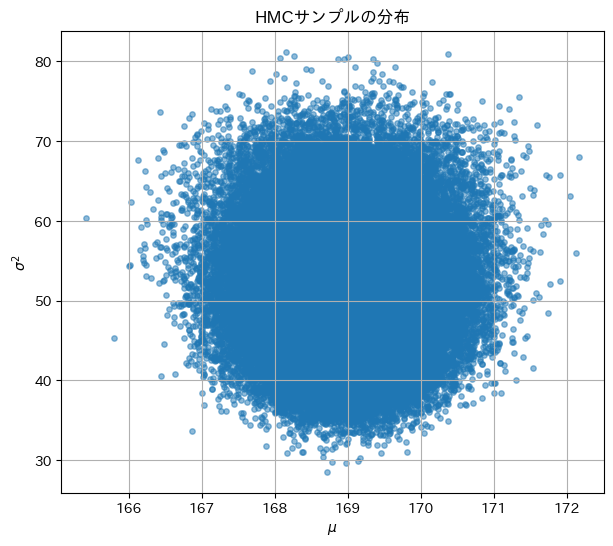

In [26]:
plt.figure(figsize=(7, 6))

plt.scatter(
	theta_samples[:, 0],
	theta_samples[:, 1],
	s=15,
	alpha=0.5
)

plt.xlabel(r"$\mu$")
plt.ylabel(r"$\sigma^2$")
plt.title(r"HMCサンプルの分布")
plt.grid()

plt.show()

In [31]:
burn_in = 50000
samples = np.array(theta_samples)
samples_after_burnin = samples[burn_in:]
mean_theta = np.mean(samples_after_burnin, axis=0)

print("バーンイン =", burn_in)
print("バーンイン後のサンプル数 =", len(samples_after_burnin))
print("theta の平均 =", mean_theta)

バーンイン = 50000
バーンイン後のサンプル数 = 50001
theta の平均 = [168.9554499   51.47042491]


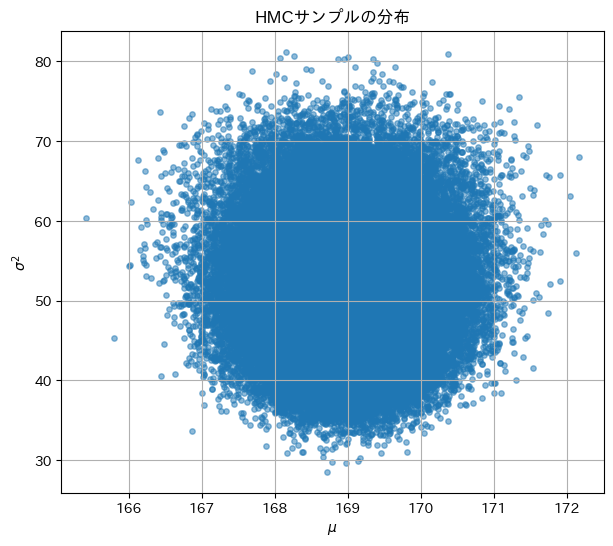

In [32]:
samples = np.array(theta_samples)

plt.figure(figsize=(7, 6))

plt.scatter(
	samples[:, 0],
	samples[:, 1],
	s=15,
	alpha=0.5
)

plt.xlabel(r"$\mu$")
plt.ylabel(r"$\sigma^2$")
plt.title(r"HMCサンプルの分布")

plt.grid()
plt.show()